# 🧠 Sesiunea 16 · Prima rețea neuronală în PyTorch

Construim o rețea foarte simplă pentru a recunoaște haine din Fashion-MNIST.

Vedem concret: input, scoruri, loss, zero_grad, backward și optimizer.step.


## 1 · Pregătire


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)


device: cpu


## 2 · Un neuron, foarte simplu

Un neuron înmulțește inputurile cu greutăți, adună bias-ul și aplică o funcție.


In [ ]:
intrari = torch.tensor([0.9, 0.7, 1.0])
greutati = torch.tensor([2.0, 3.0, -1.0])
bias = -2.0
suma = (intrari * greutati).sum() + bias
print("suma:", suma.item())
print("ieșire sigmoid:", torch.sigmoid(suma).item())


suma: 0.8999998569488525
ieșire sigmoid: 0.7109494805335999


### Exercițiul 1

Schimbă valorile din intrari și observă ieșirea neuronului.


## 3 · Tensiuni și shape-uri

Un batch de imagini are forma [batch, canale, înălțime, lățime].


In [ ]:
scalar = torch.tensor(7.0)
imagine = torch.zeros(1, 28, 28)
batch = torch.zeros(64, 1, 28, 28)
print("scalar:", tuple(scalar.shape))
print("imagine:", tuple(imagine.shape))
print("batch:", tuple(batch.shape))

# 64 - nr de imagini
# 1 - greyscale, 3 - color
# 28, 28 - dimensiunea imaginii

scalar: ()
imagine: (1, 28, 28)
batch: (64, 1, 28, 28)


### Exercițiul 2

În shape-ul (64, 1, 28, 28), ce înseamnă fiecare număr?


## 4 · Fashion-MNIST

De aici folosim imagini cu haine. Fiecare imagine are 28×28 pixeli și una dintre cele 10 clase.


In [14]:
transform = transforms.ToTensor()

train_set = datasets.FashionMNIST("data", train=True, download=True, transform=transform)
test_set = datasets.FashionMNIST("data", train=False, download=True, transform=transform)

clase = ["tricou", "pantaloni", "pulover", "rochie", "palton", "sandală", "cămașă", "adidas", "geantă", "gheată"]

# FashionMNIST 
# tricou 1
# pantaloni 2 
# pulover 3

train_loader = DataLoader(Subset(train_set, range(10000)), batch_size=64, shuffle=True)
test_loader = DataLoader(Subset(test_set, range(2000)), batch_size=256)

print("train:", len(train_loader.dataset), "| test:", len(test_loader.dataset))


train: 10000 | test: 2000


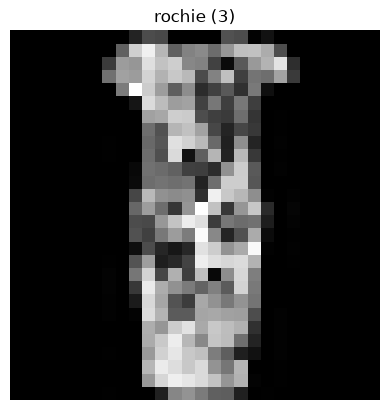

In [16]:
INDEX = 100
imagine, eticheta = test_set[INDEX]
plt.imshow(imagine.squeeze(), cmap="gray")
plt.title(f"{clase[eticheta]} ({eticheta})")
plt.axis("off")
plt.show()


## 5 · Prima rețea

Folosim cea mai simplă rețea pentru 10 clase:

Flatten → Linear(784, 10)


In [ ]:
model = nn.Sequential(nn.Flatten(), nn.Linear(784, 10)).to(device)
print(model)
print("parametri:", sum(p.numel() for p in model.parameters()))
x, y = next(iter(train_loader))
print("input:", tuple(x.shape), "output:", tuple(model(x.to(device)).shape))


Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=10, bias=True)
)
parametri: 7850
input: (64, 1, 28, 28) output: (64, 10)


## 6 · Predicția înainte de antrenare


real: rochie | prezis: geantă


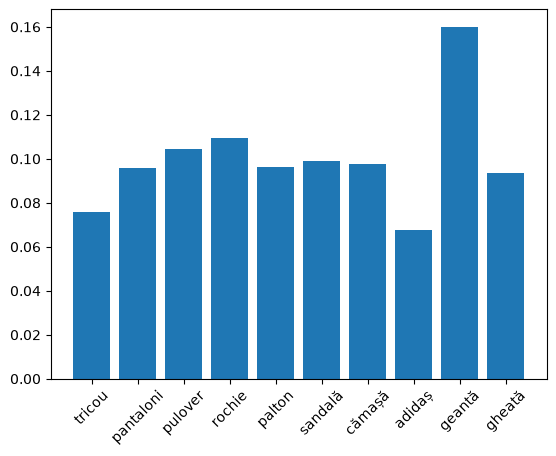

In [7]:
model.eval()
with torch.no_grad():
    probabilitati = model(x.to(device)).softmax(1)[0]
pred = probabilitati.argmax().item()
print("real:", clase[y[0]], "| prezis:", clase[pred])
plt.bar(range(10), probabilitati.cpu())
plt.xticks(range(10), clase, rotation=45)
plt.show()


## 7 · Backpropagation, pas cu pas

Pe un singur batch facem forward, loss, zero_grad, backward și update.


In [8]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)
x_batch, y_batch = next(iter(train_loader))
x_batch, y_batch = x_batch.to(device), y_batch.to(device)

scoruri = model(x_batch)
loss = loss_fn(scoruri, y_batch)
print("loss:", loss.item())

optimizer.zero_grad()
loss.backward()
print("gradient calculat:", model[1].weight.grad is not None)
optimizer.step()
print("greutățile au fost actualizate")


loss: 2.2717537879943848
gradient calculat: True
greutățile au fost actualizate


## 8 · Antrenăm o epocă


epoca 1, lot 0: loss = 2.155
epoca 1, lot 40: loss = 0.868
epoca 1, lot 80: loss = 0.894
epoca 1, lot 120: loss = 0.897


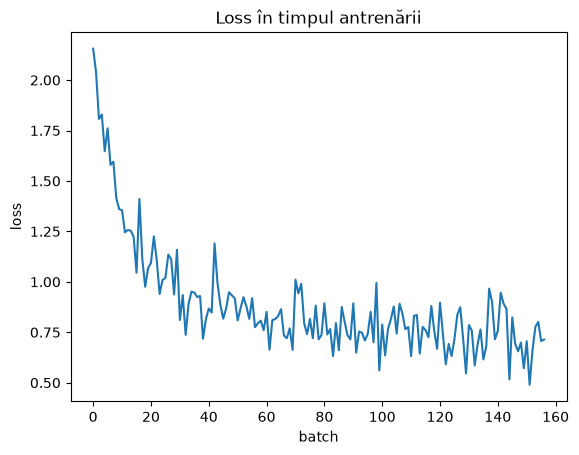

In [9]:
EPOCI = 1
lossuri = []
for epoca in range(EPOCI):
    model.train()
    for lot, (x_batch, y_batch) in enumerate(train_loader):
        x_batch, y_batch = x_batch.to(device), y_batch.to(device)
        loss = loss_fn(model(x_batch), y_batch)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        lossuri.append(loss.item())
        if lot % 40 == 0:
            print(f"epoca {epoca + 1}, lot {lot}: loss = {loss.item():.3f}")
plt.plot(lossuri)
plt.title("Loss în timpul antrenării")
plt.xlabel("batch")
plt.ylabel("loss")
plt.show()


### Exercițiul 3

Schimbă EPOCI din 1 în 2 și compară graficul loss-ului.


## 9 · Vedem ce a învățat modelul


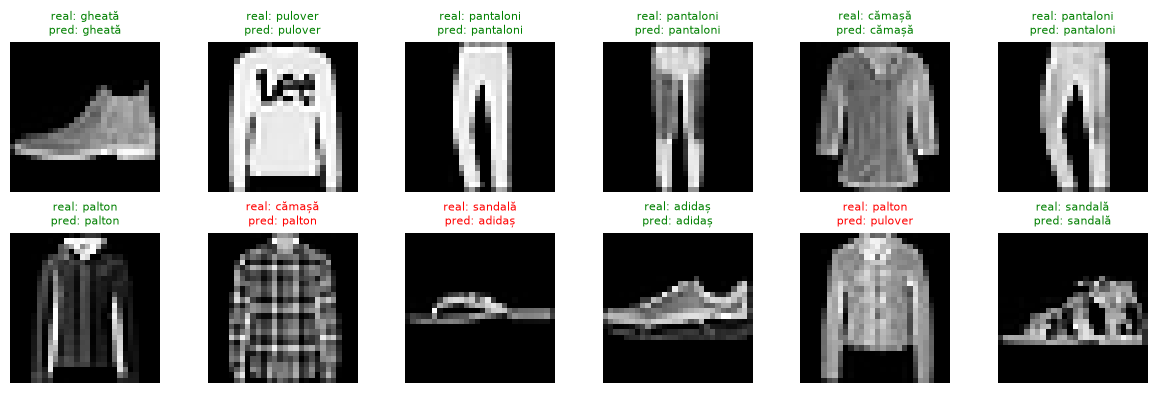

In [10]:
model.eval()
x_test, y_test = next(iter(test_loader))
with torch.no_grad():
    predictii = model(x_test.to(device)).argmax(1).cpu()
fig, ax = plt.subplots(2, 6, figsize=(12, 4))
for a, imagine, real, pred in zip(ax.flat, x_test[:12], y_test[:12], predictii[:12]):
    a.imshow(imagine.squeeze(), cmap="gray")
    a.set_title(f"real: {clase[real]}\npred: {clase[pred]}", color="green" if real == pred else "red", fontsize=8)
    a.axis("off")
plt.tight_layout()
plt.show()


## Recapitulare

Forward produce scoruri. Loss măsoară greșeala. zero_grad șterge gradientul vechi. backward calculează gradientul. optimizer.step modifică greutățile.
